In [1]:
# 1. Desinstalar versiones previas que causen conflictos
!pip uninstall -y -q keras-nlp keras-hub keras-cv

# 2. Instalar Keras 3 y el ecosistema de visión oficial
!pip install --upgrade -q keras keras-cv

# 3. Configurar el backend de TensorFlow antes de cualquier importación
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

# 4. Verificar GPU
import tensorflow as tf
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"¡Excelente! Colab ha asignado la siguiente GPU: {gpu_devices[0]}")
else:
    print("ADVERTENCIA: Asegúrate de activar la GPU en Entorno de ejecución -> Cambiar tipo de entorno.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 650.7/650.7 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.8/950.8 kB 41.6 MB/s eta 0:00:00
¡Excelente! Colab ha asignado la siguiente GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [2]:
import keras
import keras_cv
# Acceso directo al modelo maduro en el ecosistema Keras 3
from keras_cv.models import StableDiffusion
import numpy as np
from PIL import Image

print(f"Versión de Keras: {keras.__version__}")
print(f"Versión de Keras CV: {keras_cv.__version__}")
print(f"Backend activo: {keras.config.backend()}")

Versión de Keras: 3.14.1
Versión de Keras CV: 0.9.0
Backend activo: tensorflow


In [3]:
print("Descargando pesos de Stable Diffusion v1.5...")
# Inicializamos el objeto contenedor
sd_model = StableDiffusion(img_height=512, img_width=512, jit_compile=True)

print("¡Pipeline cargado con éxito!")

# Extraemos los sub-componentes internos con los nombres exactos de Keras CV
text_encoder = sd_model.text_encoder
unet = sd_model.diffusion_model
vae = sd_model.decoder

Descargando pesos de Stable Diffusion v1.5...
By using this model checkpoint, you acknowledge that its usage is subject to the terms of the CreativeML Open RAIL-M license at https://raw.githubusercontent.com/CompVis/stable-diffusion/main/LICENSE
¡Pipeline cargado con éxito!
492466864/492466864 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
3439090152/3439090152 ━━━━━━━━━━━━━━━━━━━━ 107s 0us/step
198180272/198180272 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [4]:
# Parámetros de la simulación
#prompt = "An oil painting of an astronaut cat on Mars, high quality"

prompt = "A highly detailed, photorealistic oil painting of a brave astronaut cat exploring a vast, red Martian landscape under a golden sunset, dramatic lighting, epic scale, award-winning photography"
batch_size = 1
height = 512
width = 512
num_steps = 100
cfg_scale = 5

print("--- PASO 1 & 2: TEXTO Y ESPACIO LATENTE ---")

# 1. Obtención de Embeddings de CLIP
# En KerasCV, el método público oficial y estable para codificar el texto es 'encode_text'
context = sd_model.encode_text(prompt)

print(f"Dimensiones Contexto de Texto (con CFG duplicado): {context.shape}")
print("-> [Formato: Batch*2, Tokens (77), Dimensión de Embedding (768)]\n")

# 2. Creación del Ruido Inicial en el Espacio Latente (Compresión de factor 8)
latent_height = height // 8
latent_width = width // 8

# Generamos el ruido gaussiano inicial usando las utilidades nativas de Keras
latents = keras.random.normal(
    shape=(batch_size, latent_height, latent_width, 4),
    mean=0.0,
    stddev=1.0
)

print(f"Dimensiones del ruido en el Espacio Latente: {latents.shape}")
print("-> [Formato Keras/TF: Batch (1), Alto (64), Ancho (64), Canales Latentes (4)]")

--- PASO 1 & 2: TEXTO Y ESPACIO LATENTE ---
1356917/1356917 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensiones Contexto de Texto (con CFG duplicado): (1, 77, 768)
-> [Formato: Batch*2, Tokens (77), Dimensión de Embedding (768)]

Dimensiones del ruido en el Espacio Latente: (1, 64, 64, 4)
-> [Formato Keras/TF: Batch (1), Alto (64), Ancho (64), Canales Latentes (4)]


In [5]:
print("--- PASO 3: EJECUTANDO BUCLE DE DIFUSIÓN EN GPU ---")

# 1. Definimos los timesteps de forma lineal (mapeados de 1000 a 0)
timesteps = np.linspace(1000, 0, num_steps + 1, dtype=np.int64)[:-1]

# Aseguramos que los latentes y el contexto compartan el mismo tipo de tensor nativo de TF
latents = tf.convert_to_tensor(latents, dtype=tf.float32)
context = tf.convert_to_tensor(context, dtype=tf.float32)

step_size = 1.0 / num_steps

# 2. Iniciamos el ciclo de remoción de ruido
for i, t in enumerate(timesteps):
    # Duplicamos la entrada latente para procesar CFG usando TensorFlow nativo
    latent_model_input = tf.concat([latents] * 2, axis=0)

    # Duplicamos el contexto para CFG, ya que el unet espera batch_size * 2
    duplicated_context = tf.concat([context] * 2, axis=0)

    # Generamos el embedding del timestep. El unet espera esto ya embebido.
    # Usamos batch_size=2 para CFG, para que el shape sea (2, 320).
    timestep_embedding = sd_model._get_timestep_embedding(t, batch_size=2)

    # CORRECCIÓN: Pasamos los 3 tensores dentro de una única lista posicional
    # El orden requerido por el grafo de KerasCV es: [latents, timestep_embedding, duplicated_context]
    noise_pred = unet([latent_model_input, timestep_embedding, duplicated_context])

    # Separamos las predicciones utilizando la división nativa de TensorFlow
    noise_pred_uncond, noise_pred_text = tf.split(noise_pred, 2, axis=0)

    # Aplicamos la ecuación de la Guía Libre de Clasificador (CFG)
    noise_pred = noise_pred_uncond + cfg_scale * (noise_pred_text - noise_pred_uncond)

    # 3. Actualización del espacio latente (Remoción del ruido estimado)
    latents = latents - step_size * noise_pred

    # Imprimir progreso cada 10 pasos
    if (i + 1) % 10 == 0 or i == 0:
        print(f"Paso {i+1:02d}/{num_steps} | Evaluando t = {int(t):4d} | Latente: {latents.shape}")

print("\nProceso de difusión completado. El mapa latente está limpio de ruido.")

--- PASO 3: EJECUTANDO BUCLE DE DIFUSIÓN EN GPU ---
Paso 01/100 | Evaluando t = 1000 | Latente: (1, 64, 64, 4)
Paso 10/100 | Evaluando t =  910 | Latente: (1, 64, 64, 4)
Paso 20/100 | Evaluando t =  810 | Latente: (1, 64, 64, 4)
Paso 30/100 | Evaluando t =  710 | Latente: (1, 64, 64, 4)
Paso 40/100 | Evaluando t =  610 | Latente: (1, 64, 64, 4)
Paso 50/100 | Evaluando t =  510 | Latente: (1, 64, 64, 4)
Paso 60/100 | Evaluando t =  410 | Latente: (1, 64, 64, 4)
Paso 70/100 | Evaluando t =  310 | Latente: (1, 64, 64, 4)
Paso 80/100 | Evaluando t =  210 | Latente: (1, 64, 64, 4)
Paso 90/100 | Evaluando t =  110 | Latente: (1, 64, 64, 4)
Paso 100/100 | Evaluando t =   10 | Latente: (1, 64, 64, 4)

Proceso de difusión completado. El mapa latente está limpio de ruido.


--- PASO 4: DECODIFICACIÓN DEL VAE ---
Dimensiones de la salida del VAE (Píxeles): (1, 512, 512, 3)
-> [Formato: Batch (1), Alto (512), Ancho (512), Canales RGB (3)]

Resultado final generado:


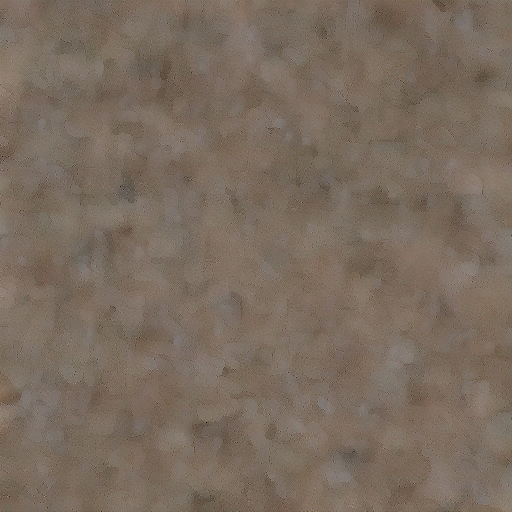

In [6]:
print("--- PASO 4: DECODIFICACIÓN DEL VAE ---")

# El Decoder del VAE expande el latente purificado de vuelta al espacio de píxeles
decoded_images = vae(latents)
print(f"Dimensiones de la salida del VAE (Píxeles): {decoded_images.shape}")
print("-> [Formato: Batch (1), Alto (512), Ancho (512), Canales RGB (3)]\n")

# Post-procesamiento matemático usando operaciones de Keras
decoded_images = keras.ops.clip(decoded_images, -1.0, 1.0)
decoded_images = (decoded_images + 1.0) / 2.0  # Mapeo de [-1, 1] a [0, 1]
decoded_images = keras.ops.convert_to_numpy(decoded_images * 255.0).astype(np.uint8)

# Convertir a imagen PIL y desplegar directamente en la celda de Colab
final_image = Image.fromarray(decoded_images[0])
print("Resultado final generado:")
display(final_image)